# Species and Genus Relative Abundance Joyplots Over Time (Recalled Species)

Ridgeline (joyplot) visualizations of the temporal relative abundance trajectories across seasonal plant timepoints (`t01`–`t28`, November 2023 – March 2024).

### Data & Definitions
- **Data source:** `Oct_2026_recalled_species/lic16s_species_relabund.csv` (cleaned as in the rest of `Recalled_species_update_results`: `AbundR >= 1`, seasonal plant samples `sample.type == "plant"` and `seascirc == "seasonal"`).
- **Relative abundance:** Within each sample, taxon reads (`Abundance`) are summed per Species (or per Genus, using the `Genus` column of the recalled-species table) and normalised to percentage of sample reads (0–100%, with absent taxa = 0). Timepoint trajectories are the mean relative abundance across the plant samples at each seasonal timepoint (`t01`–`t28`).
- **Prevalence classes** (across all 224 seasonal plant samples, matching `core_and_rare_species_definitions_and_temporal_patterns.ipynb`):
  - **Core:** prevalence > 80%
  - **Accessory:** 10% ≤ prevalence ≤ 80%
  - **Rare:** prevalence < 10%

### Joyplot Structure
- **Per-taxon max normalisation (0–1):** Each ridge shows a taxon's mean relative abundance at each timepoint divided by its maximum timepoint-mean abundance, allowing temporal patterns of both dominant and low-abundance taxa to be compared directly.
- **Ordering:** Taxa are ordered from top to bottom by their **temporal center of mass** (abundance-weighted mean timepoint index), revealing the seasonal succession from November (`t01`) through March (`t28`).
- **Four plots for Species and four plots for Genus:**
  1. **All taxa** (Top 40 by mean relative abundance with labels, plus a compact joyplot of all taxa)
  2. **Core taxa** (All core taxa with labels)
  3. **Accessory taxa** (Top 40 by mean relative abundance with labels, plus a compact joyplot of all accessory taxa)
  4. **Rare taxa** (Top 40 by mean relative abundance with labels, plus a compact joyplot of all rare taxa)


In [1]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import seaborn as sns
from scipy.interpolate import PchipInterpolator

pd.options.display.max_columns = 50
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42
plt.rcParams["svg.fonttype"] = "none"

figure_dir = Path("/Users/michael/Git/Outdoor_microbiome/Recalled_species_update_results/Figures")
figure_dir.mkdir(parents=True, exist_ok=True)


In [2]:
### Load recalled species table and filter to seasonal plant samples
### Species under 0.05% of a sample (AbundR == 0) are dropped, matching the other notebooks
min_abundR = 1
samples_to_drop = []  # ["LIC148", "LIC162", "LIC577", "LIC584"]

core_threshold = 0.80
rare_threshold = 0.10
unassigned_labels = {"unassigned", "na", "none", ""}

microbiome_abundance = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/Oct_2026_recalled_species/lic16s_species_relabund.csv"
)
microbiome_abundance = microbiome_abundance.loc[
    (microbiome_abundance["AbundR"] >= min_abundR)
    & ~microbiome_abundance["Sample"].isin(samples_to_drop)
].copy()

# Circadian timepoints start with "c"
microbiome_abundance["seascirc"] = np.where(
    microbiome_abundance["timepoint"].str.startswith("c"), "circadian", "seasonal"
)
long_term_microbiome = microbiome_abundance.loc[
    (microbiome_abundance["sample.type"] == "plant")
    & (microbiome_abundance["seascirc"] == "seasonal")
].rename(columns={"Sample": "sampID"})

# Extract ordered seasonal timepoint metadata (t01..t28)
timepoint_meta = (
    long_term_microbiome.groupby("timepoint", as_index=False)
    .agg(
        n_samples=("sampID", "nunique"),
        day=("day", "first"),
        time=("time", "first"),
        daysincestart=("daysincestart", "first"),
    )
)
timepoint_meta["tp_num"] = timepoint_meta["timepoint"].str.lstrip("t").astype(int)
timepoint_meta["datetime"] = pd.to_datetime(
    timepoint_meta["day"] + " " + timepoint_meta["time"], format="%m/%d/%y %H:%M"
)
timepoint_meta["month"] = timepoint_meta["datetime"].dt.strftime("%B")
timepoint_meta = timepoint_meta.sort_values("tp_num").reset_index(drop=True)

print(f"Seasonal plant samples: {long_term_microbiome['sampID'].nunique()}")
print(f"Seasonal timepoints: {len(timepoint_meta)} ({timepoint_meta['timepoint'].iloc[0]} to {timepoint_meta['timepoint'].iloc[-1]})")
timepoint_meta.head()


Seasonal plant samples: 224
Seasonal timepoints: 28 (t01 to t28)


,timepoint,n_samples,day,time,daysincestart,tp_num,datetime,month
0,t01,8,11/1/23,8:00,0,1,2023-11-01 08:00:00,November
1,t02,8,11/7/23,8:00,6,2,2023-11-07 08:00:00,November
2,t03,8,11/14/23,8:00,13,3,2023-11-14 08:00:00,November
3,t04,8,11/17/23,8:00,16,4,2023-11-17 08:00:00,November
4,t05,8,11/21/23,8:00,20,5,2023-11-21 08:00:00,November


In [3]:
def prepare_rank_data(df, tax_col, sample_col="sampID", core_thresh=0.80, rare_thresh=0.10):
    """Build sample x taxon % abundance matrix, timepoint x taxon mean % abundance matrix,
    and prevalence classification table (Core, Accessory, Rare) for a taxonomic rank."""
    total_samples_all = df[sample_col].dropna().unique()
    n_total_samples = len(total_samples_all)

    working = df[[sample_col, "timepoint", tax_col, "Abundance"]].copy()
    working[tax_col] = working[tax_col].astype("string").str.strip()
    working = working[
        working[tax_col].notna()
        & ~working[tax_col].str.casefold().isin(unassigned_labels)
    ]

    # Sample x taxon matrix (% of sample reads, absent = 0)
    sample_taxon = pd.pivot_table(
        working,
        values="Abundance",
        index=sample_col,
        columns=tax_col,
        aggfunc="sum",
        fill_value=0.0,
    ).reindex(index=total_samples_all, fill_value=0.0)
    sample_taxon_pct = sample_taxon.div(sample_taxon.sum(axis=1), axis=0) * 100.0

    # Timepoint x taxon mean % relative abundance across samples in each timepoint
    sample_tp = df.drop_duplicates(sample_col).set_index(sample_col)["timepoint"]
    tp_order = timepoint_meta["timepoint"].tolist()
    tp_taxon_mean = (
        sample_taxon_pct.groupby(sample_tp).mean().reindex(tp_order)
    )

    # Prevalence and classification across seasonal plant samples
    n_present = (sample_taxon_pct > 0).sum(axis=0)
    prevalence = n_present / n_total_samples
    mean_abund_all = sample_taxon_pct.mean(axis=0)
    max_tp_abund = tp_taxon_mean.max(axis=0)

    # Temporal center of mass (weighted average timepoint index 0..27) and peak timepoint
    tp_indices = np.arange(len(tp_order), dtype=float)
    weights = tp_taxon_mean.to_numpy()  # shape (n_tp, n_taxa)
    col_sums = weights.sum(axis=0)
    center_of_mass = np.where(
        col_sums > 0,
        (tp_indices[:, None] * weights).sum(axis=0) / col_sums,
        0.0,
    )
    peak_tp_idx = weights.argmax(axis=0)

    taxa_info = pd.DataFrame(
        {
            tax_col: sample_taxon_pct.columns,
            "n_samples_present": n_present.values,
            "prevalence": prevalence.values,
            "mean_abund_pct": mean_abund_all.values,
            "max_tp_abund_pct": max_tp_abund.values,
            "center_of_mass_tp": center_of_mass,
            "peak_tp_idx": peak_tp_idx,
            "peak_timepoint": [tp_order[idx] for idx in peak_tp_idx],
        }
    )
    taxa_info["class"] = np.select(
        [
            taxa_info["prevalence"] > core_thresh,
            taxa_info["prevalence"] < rare_thresh,
        ],
        ["Core", "Rare"],
        default="Accessory",
    )
    taxa_info = taxa_info.sort_values(
        ["prevalence", "mean_abund_pct"], ascending=[False, False]
    ).reset_index(drop=True)

    return sample_taxon_pct, tp_taxon_mean, taxa_info


species_sample_pct, species_tp_mean, species_info = prepare_rank_data(
    long_term_microbiome, "Species"
)
genus_sample_pct, genus_tp_mean, genus_info = prepare_rank_data(
    long_term_microbiome, "Genus"
)

summary_counts = pd.DataFrame(
    {
        "Species": species_info["class"].value_counts(),
        "Genus": genus_info["class"].value_counts(),
    }
).reindex(["Core", "Accessory", "Rare"])
summary_counts.loc["Total"] = summary_counts.sum()
print("Taxon counts by prevalence class in seasonal plant samples:")
display(summary_counts)


Taxon counts by prevalence class in seasonal plant samples:


,Species,Genus
class,,
Core,40,35
Accessory,181,95
Rare,388,189
Total,609,319


In [4]:
def clean_taxon_label(name):
    """Strip GTDB rank prefix (s__, g__) for cleaner axis labels while preserving unresolved rank tags."""
    return re.sub(r"^[sgfocd]__", "", str(name).strip())


def add_month_spans(ax, timepoint_meta_df, y_axes_frac=-0.04):
    """Add contiguous seasonal month span bars and labels below the bottom axis."""
    month_colors = {
        "November": "tab:purple",
        "December": "tab:blue",
        "January": "tab:green",
        "February": "tab:orange",
        "March": "tab:red",
    }
    n_tp = len(timepoint_meta_df)
    max_x = float(n_tp - 1)
    half_gap = 0.08  # small visual separation between adjacent month bars in data units

    for month, grp in timepoint_meta_df.groupby("month", sort=False):
        start_idx = int(grp.index.min())
        end_idx = int(grp.index.max())
        left_data = 0.0 if start_idx == 0 else (start_idx - 0.5 + half_gap)
        right_data = max_x if end_idx == n_tp - 1 else (end_idx + 0.5 - half_gap)
        x0 = left_data / max_x
        x1 = right_data / max_x
        color = month_colors.get(month, "black")
        ax.annotate(
            "",
            xy=(x0, y_axes_frac),
            xycoords="axes fraction",
            xytext=(x1, y_axes_frac),
            textcoords="axes fraction",
            arrowprops=dict(
                arrowstyle="-",
                color=color,
                lw=5,
                shrinkA=0,
                shrinkB=0,
                capstyle="butt",
            ),
            annotation_clip=False,
        )
        ax.text(
            (x0 + x1) / 2,
            y_axes_frac - abs(y_axes_frac) * 0.65,
            month,
            transform=ax.transAxes,
            ha="center",
            va="top",
            fontsize=10.5,
            fontweight="bold",
            color=color,
        )


def plot_labeled_joyplot(
    tp_mean_df,
    taxa_info_df,
    tax_col,
    title,
    max_taxa=40,
    overlap=0.65,
    cmap_name="viridis_r",
    save_path=None,
):
    """Plot a labeled ridgeline (joyplot) of per-taxon max-normalised mean relative abundance
    over seasonal timepoints (t01..t28).

    - If the group has more than `max_taxa` taxa, selects the top `max_taxa` by overall mean relative abundance.
    - Orders selected taxa from top to bottom by temporal center of mass (early -> late season).
    """
    sub_info = taxa_info_df.copy()
    total_in_group = len(sub_info)
    if max_taxa is not None and total_in_group > max_taxa:
        sub_info = sub_info.nlargest(max_taxa, "mean_abund_pct").copy()
        subtitle_note = f"Top {max_taxa} of {total_in_group} by mean abundance (ordered early → late season)"
    else:
        subtitle_note = f"All {total_in_group} taxa (ordered early → late season)"

    # Order from earliest center-of-mass (top) to latest center-of-mass (bottom)
    sub_info = sub_info.sort_values(
        ["center_of_mass_tp", "peak_tp_idx", "mean_abund_pct"],
        ascending=[True, True, False],
    ).reset_index(drop=True)

    taxa_list = sub_info[tax_col].tolist()
    n_taxa = len(taxa_list)
    n_tp = len(tp_mean_df)
    x = np.arange(n_tp, dtype=float)
    x_fine = np.linspace(0, n_tp - 1, (n_tp - 1) * 12 + 1)

    step = 1.0 - overlap
    ridge_scale = 1.0
    fig_height = max(5.5, n_taxa * 0.28 + 1.8)
    fig, ax = plt.subplots(figsize=(10.5, fig_height), dpi=120)
    fig.patch.set_facecolor("white")
    ax.set_facecolor("white")

    cmap = plt.get_cmap(cmap_name)
    norm = mcolors.Normalize(vmin=0, vmax=n_tp - 1)

    yticks = []
    yticklabels_left = []

    for i, row in sub_info.iterrows():
        taxon = row[tax_col]
        y_raw = tp_mean_df[taxon].to_numpy(dtype=float)
        y_max = y_raw.max()
        y_norm = y_raw / y_max if y_max > 0 else y_raw

        # Smooth PCHIP interpolation (monotonic between timepoints, stays in [0, 1])
        interp = PchipInterpolator(x, y_norm)
        y_smooth = np.clip(interp(x_fine), 0.0, 1.0)

        baseline = -i * step
        y_curve = baseline + y_smooth * ridge_scale
        color = cmap(norm(row["center_of_mass_tp"]))

        # White occluding fill, coloured ridge fill, baseline, and crisp outline
        ax.fill_between(
            x_fine, baseline, y_curve, color="white", zorder=3 * i + 1
        )
        ax.fill_between(
            x_fine, baseline, y_curve, color=color, alpha=0.78, zorder=3 * i + 2
        )
        ax.plot(
            x_fine,
            np.full_like(x_fine, baseline),
            color="#d0d0d0",
            linewidth=0.5,
            zorder=3 * i,
        )
        ax.plot(
            x_fine, y_curve, color="#1a1a1a", linewidth=0.9, zorder=3 * i + 3
        )

        yticks.append(baseline)
        yticklabels_left.append(clean_taxon_label(taxon))

    ax.set_xlim(0, n_tp - 1)
    ax.set_ylim(-(n_taxa - 1) * step - 0.15, ridge_scale + 0.25)

    # X-axis: keep vertical timepoint grid lines, hide individual date/timepoint labels
    ax.set_xticks(x)
    ax.set_xticklabels([])
    ax.tick_params(axis="x", length=0)

    # Left Y-axis: taxon names
    ax.set_yticks(yticks)
    ax.set_yticklabels(yticklabels_left, fontsize=8.5)
    ax.tick_params(axis="y", length=0, pad=6)

    sns.despine(ax=ax, top=True, right=True, left=True)
    ax.spines["bottom"].set_color("black")
    ax.spines["bottom"].set_linewidth(1.5)
    ax.xaxis.grid(True, linestyle=":", alpha=0.35, color="#888888", zorder=0)

    ax.set_title(
        f"{title}\n({subtitle_note})",
        fontsize=13,
        fontweight="bold",
        pad=14,
    )

    # Place month span bars directly below the bottom spine
    y_span_pos = -0.25 / fig_height
    add_month_spans(ax, timepoint_meta, y_axes_frac=y_span_pos)

    plt.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, bbox_inches="tight")
        print(f"Saved figure to {save_path}")
    plt.show()


In [5]:
def plot_compact_joyplot(
    tp_mean_df,
    taxa_info_df,
    tax_col,
    title,
    cmap_name="viridis_r",
    save_path=None,
):
    """Plot a compact all-taxa ridgeline cascade (joyplot) for large groups without crowding y-axis labels.
    Every taxon in `taxa_info_df` is plotted as a horizontal ridge ordered by temporal center of mass
    (early season at top -> late season at bottom)."""
    sub_info = taxa_info_df.sort_values(
        ["center_of_mass_tp", "peak_tp_idx", "mean_abund_pct"],
        ascending=[True, True, False],
    ).reset_index(drop=True)

    taxa_list = sub_info[tax_col].tolist()
    n_taxa = len(taxa_list)
    n_tp = len(tp_mean_df)
    x = np.arange(n_tp, dtype=float)
    x_fine = np.linspace(0, n_tp - 1, (n_tp - 1) * 10 + 1)

    # Scale vertical step so total height stays compact and readable even for 300-600 taxa
    step = max(0.04, min(0.22, 22.0 / max(n_taxa, 1)))
    ridge_scale = 1.0
    fig_height = max(6.5, min(10.5, n_taxa * 0.022 + 4.0))

    fig, ax = plt.subplots(figsize=(10.5, fig_height), dpi=120)
    fig.patch.set_facecolor("white")
    ax.set_facecolor("white")

    cmap = plt.get_cmap(cmap_name)
    norm = mcolors.Normalize(vmin=0, vmax=n_tp - 1)

    # Vectorised PCHIP interpolation across all taxa at once
    Y_raw = tp_mean_df[taxa_list].to_numpy(dtype=float)  # (n_tp, n_taxa)
    Y_max = Y_raw.max(axis=0)
    Y_norm = np.divide(Y_raw, Y_max, out=np.zeros_like(Y_raw), where=Y_max > 0)
    interp = PchipInterpolator(x, Y_norm, axis=0)
    Y_smooth = np.clip(interp(x_fine), 0.0, 1.0)

    lw = 0.35 if n_taxa > 150 else 0.55
    for i in range(n_taxa):
        baseline = -i * step
        y_curve = baseline + Y_smooth[:, i] * ridge_scale
        color = cmap(norm(sub_info["center_of_mass_tp"].iloc[i]))

        ax.fill_between(
            x_fine, baseline, y_curve, color="white", zorder=2 * i + 1
        )
        ax.fill_between(
            x_fine, baseline, y_curve, color=color, alpha=0.72, zorder=2 * i + 2
        )
        ax.plot(
            x_fine, y_curve, color="#1a1a1a", linewidth=lw, alpha=0.85, zorder=2 * i + 3
        )

    ax.set_xlim(0, n_tp - 1)
    ax.set_ylim(-(n_taxa - 1) * step - 0.15, ridge_scale + 0.25)

    # X-axis: keep vertical timepoint grid lines, hide individual date/timepoint labels
    ax.set_xticks(x)
    ax.set_xticklabels([])
    ax.tick_params(axis="x", length=0)

    # Show taxon rank ticks along the left axis
    tick_indices = np.unique(
        np.linspace(0, n_taxa - 1, min(10, n_taxa), dtype=int)
    )
    ax.set_yticks([-idx * step for idx in tick_indices])
    ax.set_yticklabels([f"#{idx + 1}" for idx in tick_indices], fontsize=8.5)
    ax.set_ylabel(
        f"Taxa ordered by seasonal timing (n = {n_taxa}, early → late)",
        fontsize=10.5,
    )

    sns.despine(ax=ax, top=True, right=True)
    ax.spines["bottom"].set_color("black")
    ax.spines["bottom"].set_linewidth(1.5)
    ax.spines["left"].set_color("black")
    ax.spines["left"].set_linewidth(1.2)
    ax.xaxis.grid(True, linestyle=":", alpha=0.35, color="#888888", zorder=0)

    # Colorbar for temporal center of mass labeled by month
    sm = cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, pad=0.02, aspect=30, shrink=0.75)
    month_centers = [
        grp.index.to_numpy().mean()
        for _, grp in timepoint_meta.groupby("month", sort=False)
    ]
    month_names = [
        month for month, _ in timepoint_meta.groupby("month", sort=False)
    ]
    cbar.set_ticks(month_centers)
    cbar.set_ticklabels(month_names, fontsize=8.5)
    cbar.set_label("Temporal Center of Mass", fontsize=9.5)

    ax.set_title(
        f"{title}\n(All {n_taxa} taxa, max-normalised 0–1 per taxon, ordered early → late season)",
        fontsize=13,
        fontweight="bold",
        pad=14,
    )

    y_span_pos = -0.25 / fig_height
    add_month_spans(ax, timepoint_meta, y_axes_frac=y_span_pos)

    plt.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, bbox_inches="tight")
        print(f"Saved figure to {save_path}")
    plt.show()


---
## Part 1: Species-Level Joyplots Over Time

1. **All Species** (`n = 609`): Top 40 by mean abundance (labeled) + All 609 species (compact cascade)
2. **Core Species** (`prevalence > 80%`, `n = 40`): All 40 core species (labeled)
3. **Accessory Species** (`10% ≤ prevalence ≤ 80%`, `n = 181`): Top 40 by mean abundance (labeled) + All 181 accessory species (compact cascade)
4. **Rare Species** (`prevalence < 10%`, `n = 388`): Top 40 by mean abundance (labeled) + All 388 rare species (compact cascade)


### 1.1 All Species Over Time


Saved figure to /Users/michael/Git/Outdoor_microbiome/Recalled_species_update_results/Figures/joyplot_species_all_top40.pdf


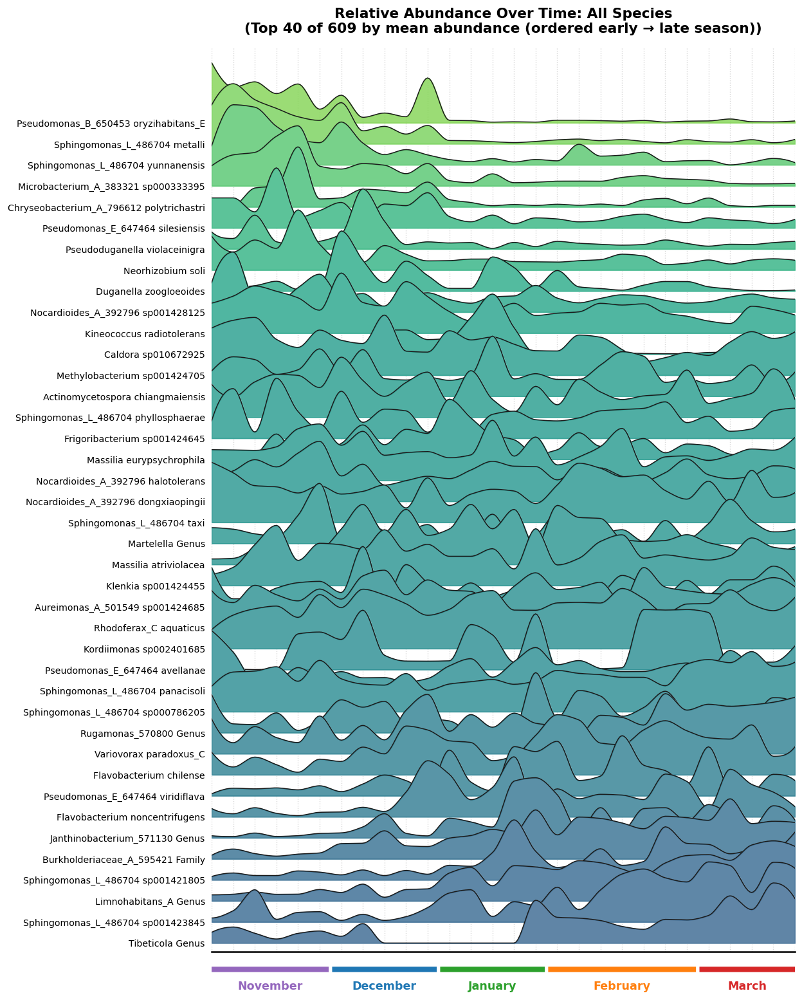

Saved figure to /Users/michael/Git/Outdoor_microbiome/Recalled_species_update_results/Figures/joyplot_species_all_compact.pdf


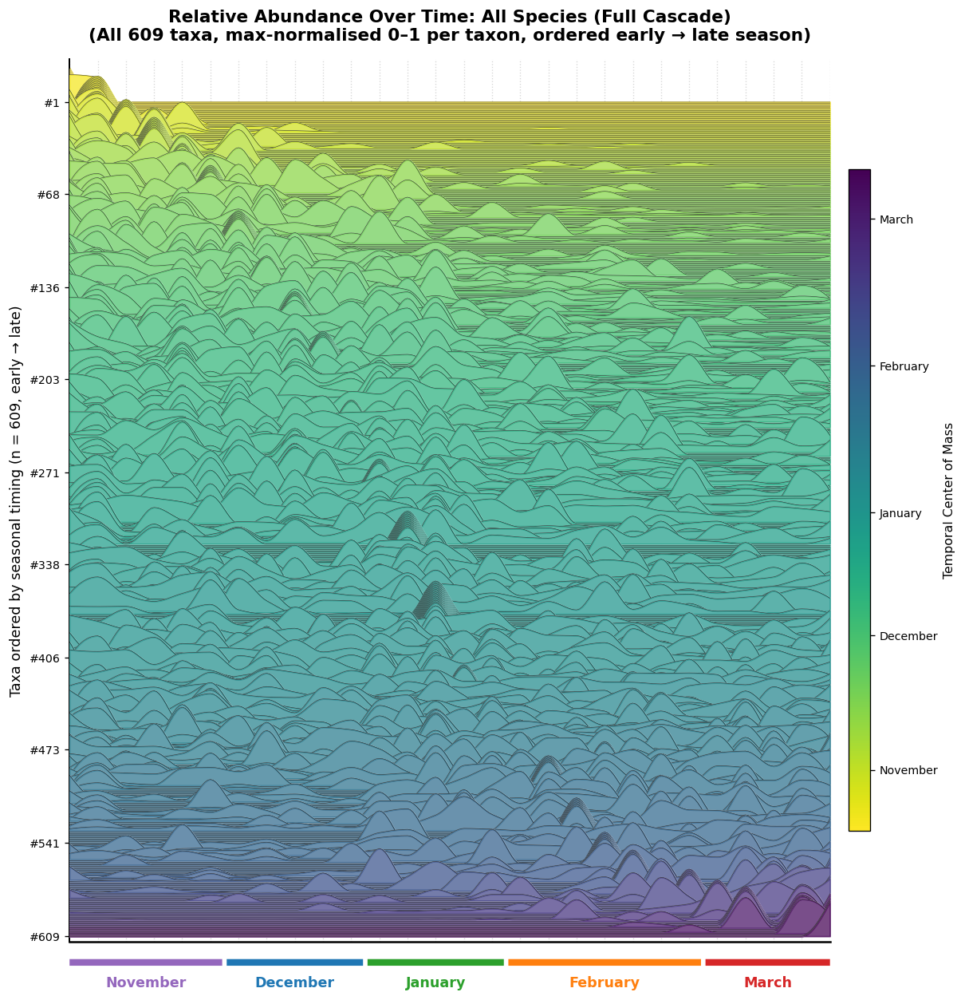

In [6]:
# 1a. Top 40 most abundant species (labeled joyplot)
plot_labeled_joyplot(
    species_tp_mean,
    species_info,
    tax_col="Species",
    title="Relative Abundance Over Time: All Species",
    max_taxa=40,
    cmap_name="viridis_r",
    save_path=figure_dir / "joyplot_species_all_top40.pdf",
)

# 1b. All 609 species (compact joyplot)
plot_compact_joyplot(
    species_tp_mean,
    species_info,
    tax_col="Species",
    title="Relative Abundance Over Time: All Species (Full Cascade)",
    cmap_name="viridis_r",
    save_path=figure_dir / "joyplot_species_all_compact.pdf",
)


### 1.2 Core Species Over Time (Prevalence > 80%)


Core species count: 40


Saved figure to /Users/michael/Git/Outdoor_microbiome/Recalled_species_update_results/Figures/joyplot_species_core.pdf


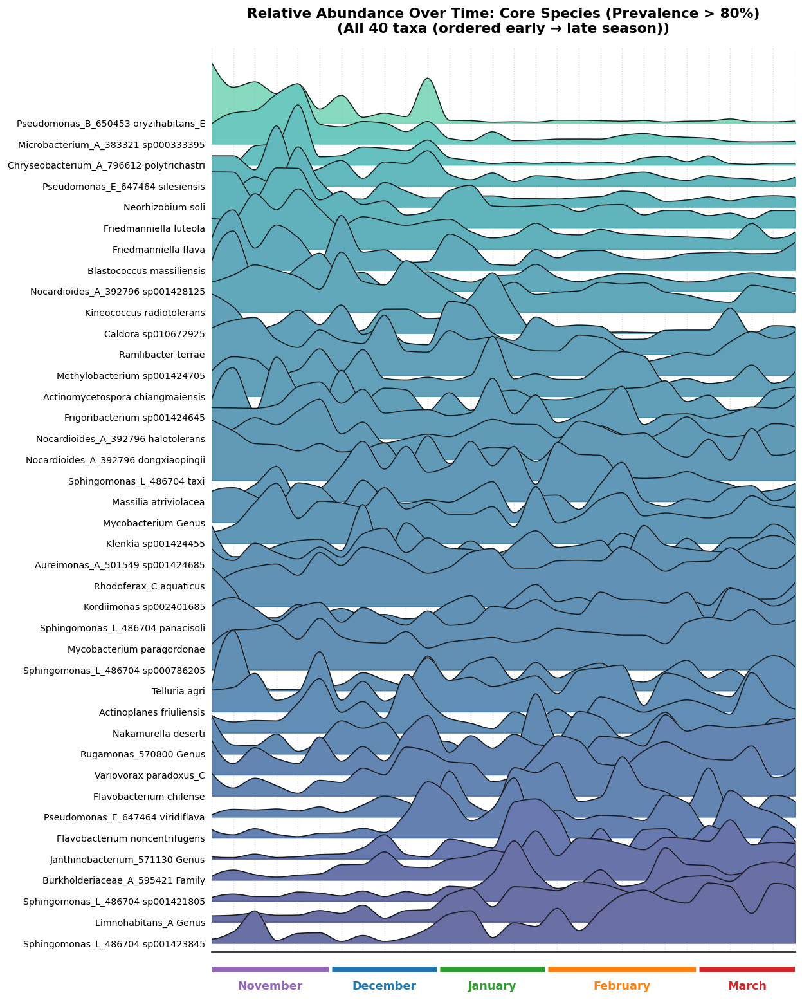

In [7]:
core_species_info = species_info.loc[species_info["class"] == "Core"].copy()
print(f"Core species count: {len(core_species_info)}")

plot_labeled_joyplot(
    species_tp_mean,
    core_species_info,
    tax_col="Species",
    title="Relative Abundance Over Time: Core Species (Prevalence > 80%)",
    max_taxa=None,
    cmap_name="mako_r",
    save_path=figure_dir / "joyplot_species_core.pdf",
)


### 1.3 Accessory Species Over Time (10% ≤ Prevalence ≤ 80%)


Accessory species count: 181


Saved figure to /Users/michael/Git/Outdoor_microbiome/Recalled_species_update_results/Figures/joyplot_species_accessory_top40.pdf


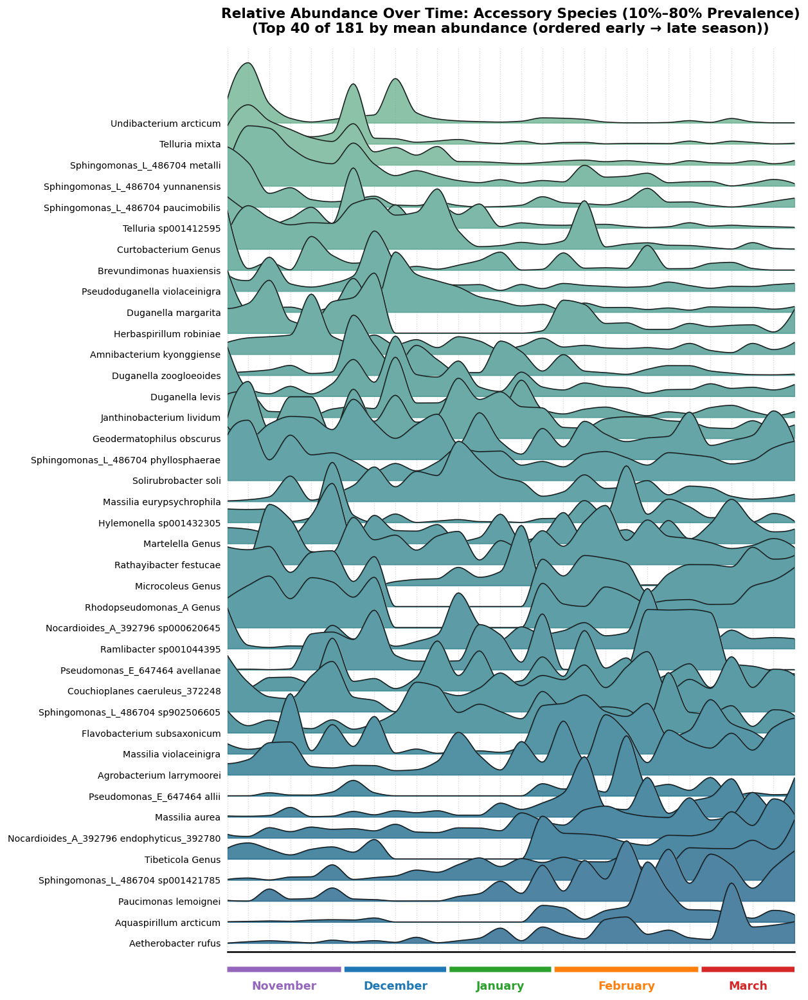

Saved figure to /Users/michael/Git/Outdoor_microbiome/Recalled_species_update_results/Figures/joyplot_species_accessory_compact.pdf


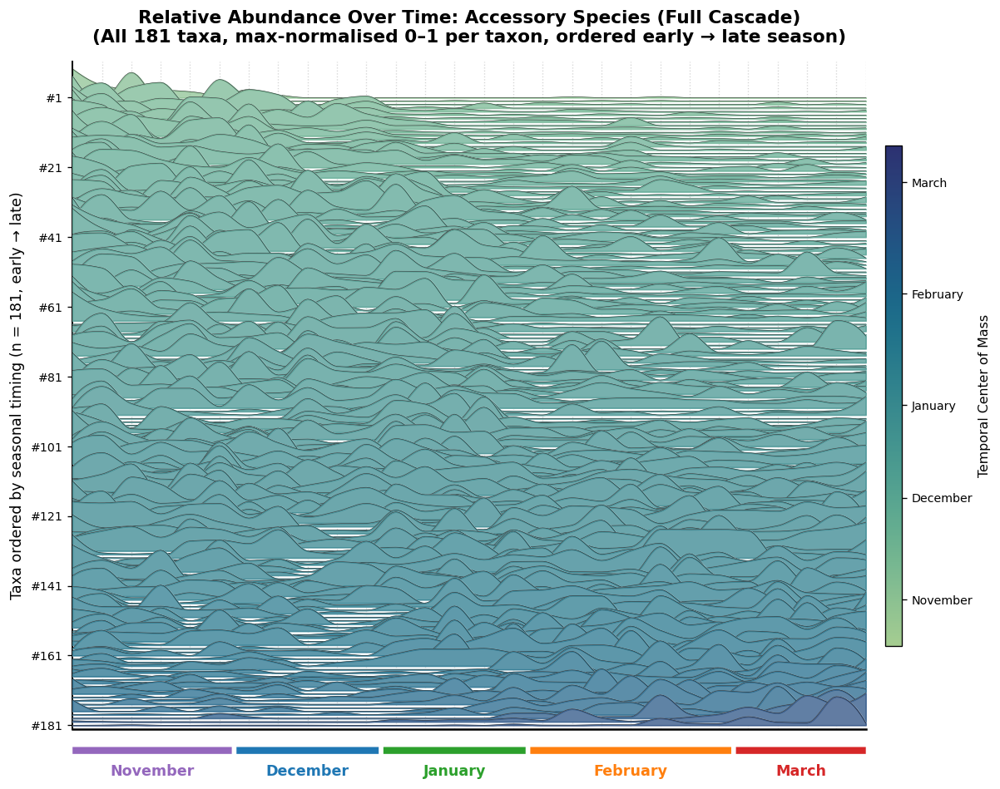

In [8]:
accessory_species_info = species_info.loc[species_info["class"] == "Accessory"].copy()
print(f"Accessory species count: {len(accessory_species_info)}")

# 3a. Top 40 accessory species by mean abundance (labeled joyplot)
plot_labeled_joyplot(
    species_tp_mean,
    accessory_species_info,
    tax_col="Species",
    title="Relative Abundance Over Time: Accessory Species (10%–80% Prevalence)",
    max_taxa=40,
    cmap_name="crest",
    save_path=figure_dir / "joyplot_species_accessory_top40.pdf",
)

# 3b. All 181 accessory species (compact joyplot)
plot_compact_joyplot(
    species_tp_mean,
    accessory_species_info,
    tax_col="Species",
    title="Relative Abundance Over Time: Accessory Species (Full Cascade)",
    cmap_name="crest",
    save_path=figure_dir / "joyplot_species_accessory_compact.pdf",
)


### 1.4 Rare Species Over Time (Prevalence < 10%)


Rare species count: 388


Saved figure to /Users/michael/Git/Outdoor_microbiome/Recalled_species_update_results/Figures/joyplot_species_rare_top40.pdf


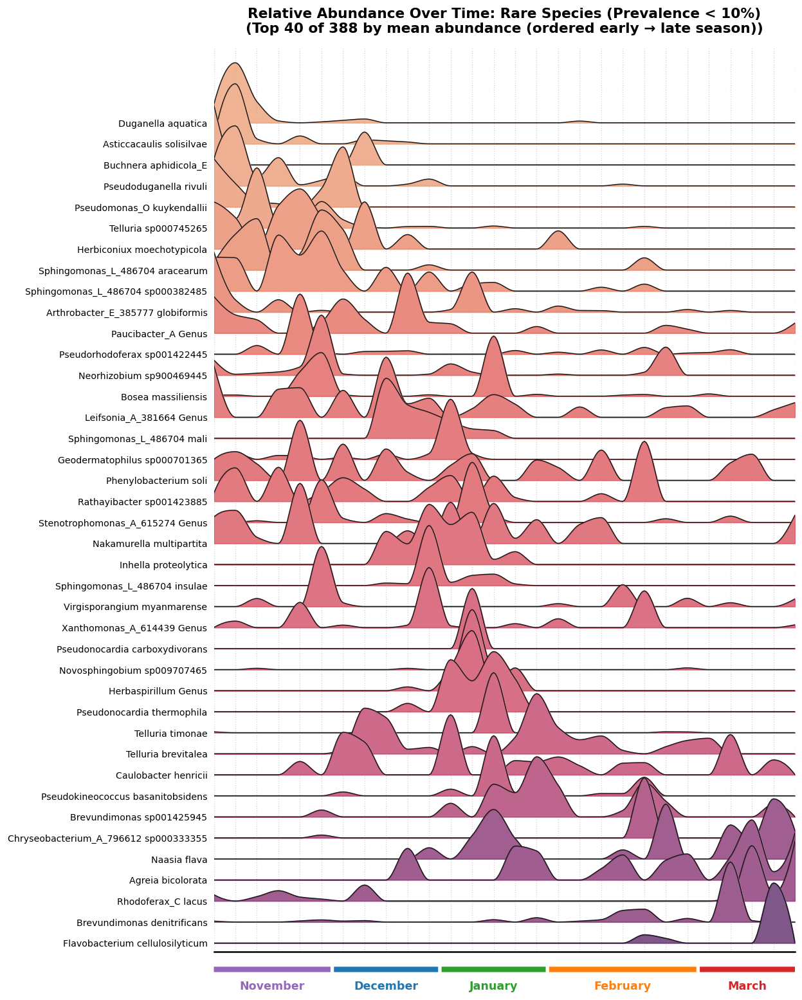

Saved figure to /Users/michael/Git/Outdoor_microbiome/Recalled_species_update_results/Figures/joyplot_species_rare_compact.pdf


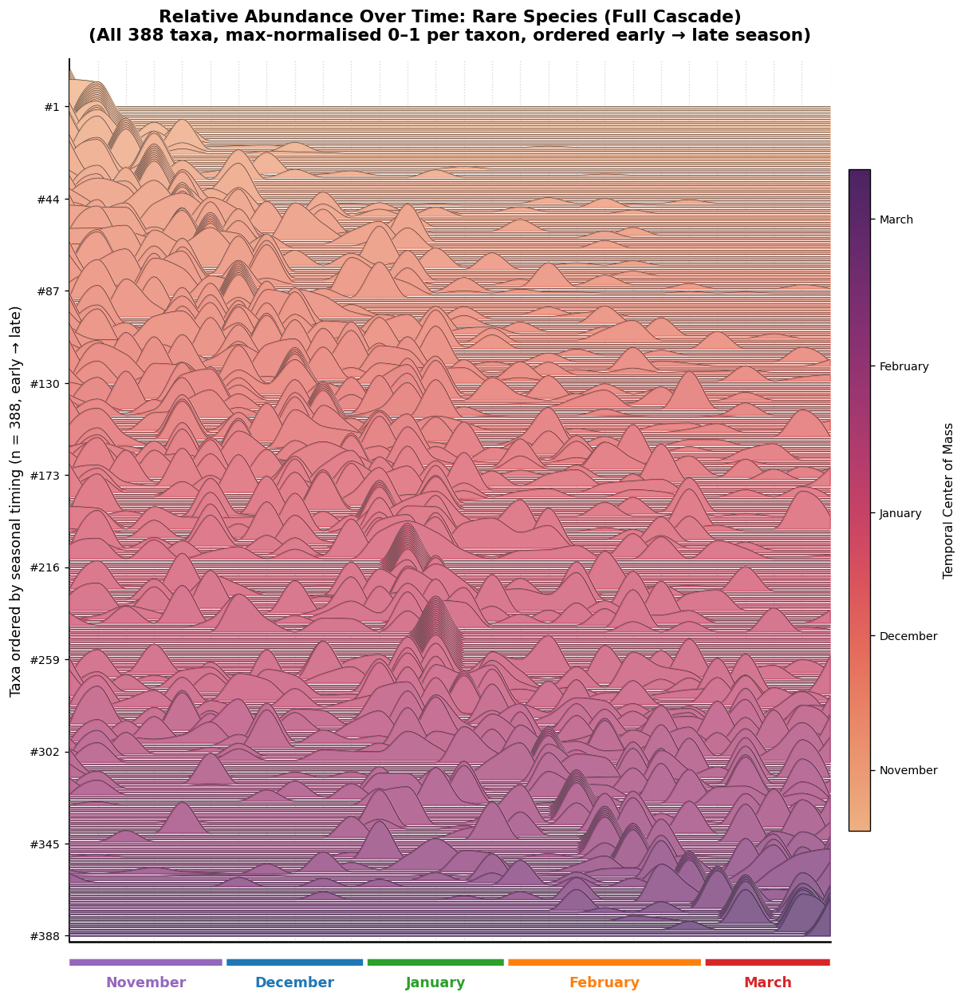

In [9]:
rare_species_info = species_info.loc[species_info["class"] == "Rare"].copy()
print(f"Rare species count: {len(rare_species_info)}")

# 4a. Top 40 rare species by mean abundance (labeled joyplot)
plot_labeled_joyplot(
    species_tp_mean,
    rare_species_info,
    tax_col="Species",
    title="Relative Abundance Over Time: Rare Species (Prevalence < 10%)",
    max_taxa=40,
    cmap_name="flare",
    save_path=figure_dir / "joyplot_species_rare_top40.pdf",
)

# 4b. All 388 rare species (compact joyplot)
plot_compact_joyplot(
    species_tp_mean,
    rare_species_info,
    tax_col="Species",
    title="Relative Abundance Over Time: Rare Species (Full Cascade)",
    cmap_name="flare",
    save_path=figure_dir / "joyplot_species_rare_compact.pdf",
)


---
## Part 2: Genus-Level Joyplots Over Time

Using the `Genus` column aggregated from `Oct_2026_recalled_species/lic16s_species_relabund.csv` across seasonal plant samples:
1. **All Genera** (`n = 319`): Top 40 by mean abundance (labeled) + All 319 genera (compact cascade)
2. **Core Genera** (`prevalence > 80%`, `n = 35`): All 35 core genera (labeled)
3. **Accessory Genera** (`10% ≤ prevalence ≤ 80%`): Top 40 by mean abundance (labeled) + All accessory genera (compact cascade)
4. **Rare Genera** (`prevalence < 10%`): Top 40 by mean abundance (labeled) + All rare genera (compact cascade)


### 2.1 All Genera Over Time


Saved figure to /Users/michael/Git/Outdoor_microbiome/Recalled_species_update_results/Figures/joyplot_genus_all_top40.pdf


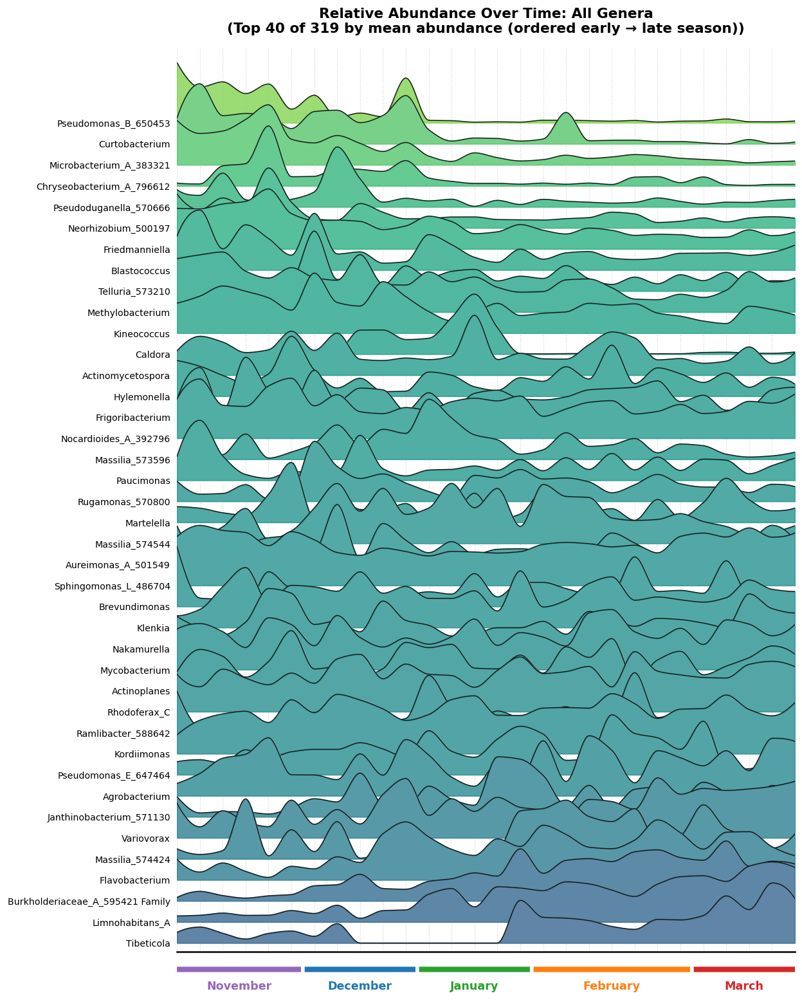

Saved figure to /Users/michael/Git/Outdoor_microbiome/Recalled_species_update_results/Figures/joyplot_genus_all_compact.pdf


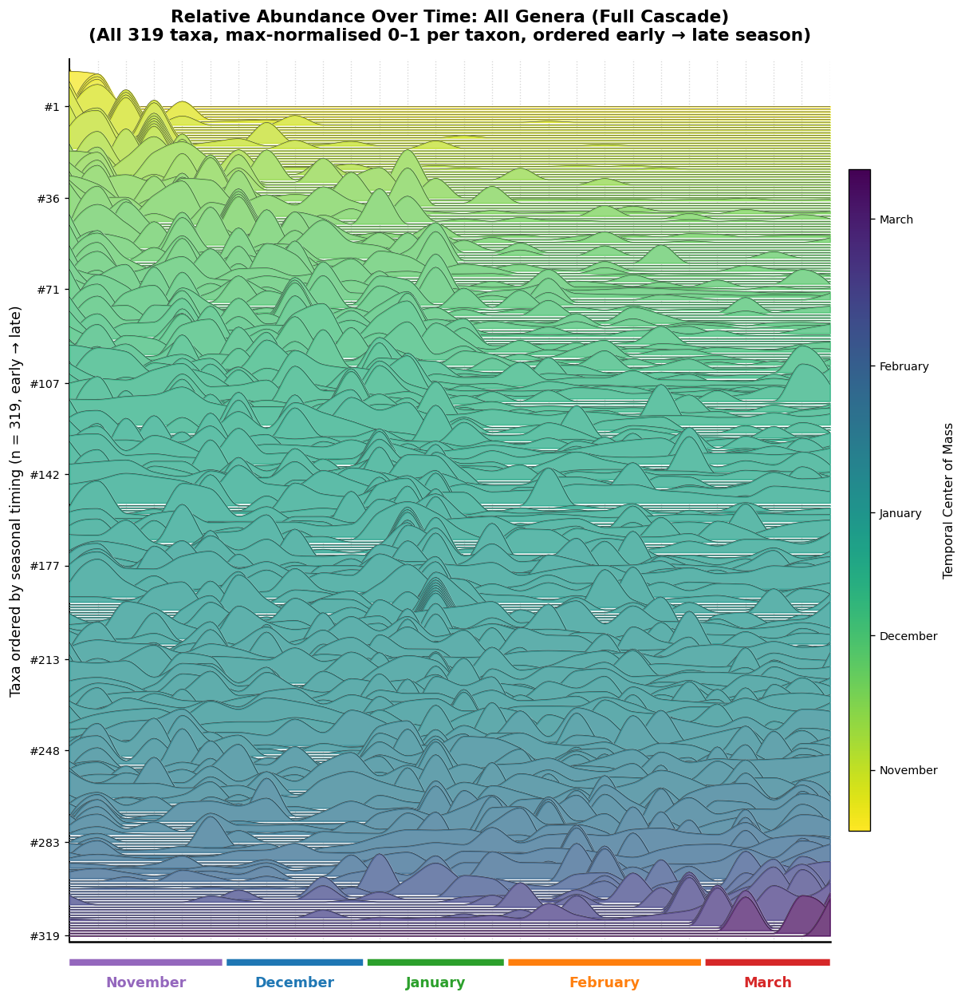

In [10]:
# 5a. Top 40 most abundant genera (labeled joyplot)
plot_labeled_joyplot(
    genus_tp_mean,
    genus_info,
    tax_col="Genus",
    title="Relative Abundance Over Time: All Genera",
    max_taxa=40,
    cmap_name="viridis_r",
    save_path=figure_dir / "joyplot_genus_all_top40.pdf",
)

# 5b. All 319 genera (compact joyplot)
plot_compact_joyplot(
    genus_tp_mean,
    genus_info,
    tax_col="Genus",
    title="Relative Abundance Over Time: All Genera (Full Cascade)",
    cmap_name="viridis_r",
    save_path=figure_dir / "joyplot_genus_all_compact.pdf",
)


### 2.2 Core Genera Over Time (Prevalence > 80%)


Core genera count: 35


Saved figure to /Users/michael/Git/Outdoor_microbiome/Recalled_species_update_results/Figures/joyplot_genus_core.pdf


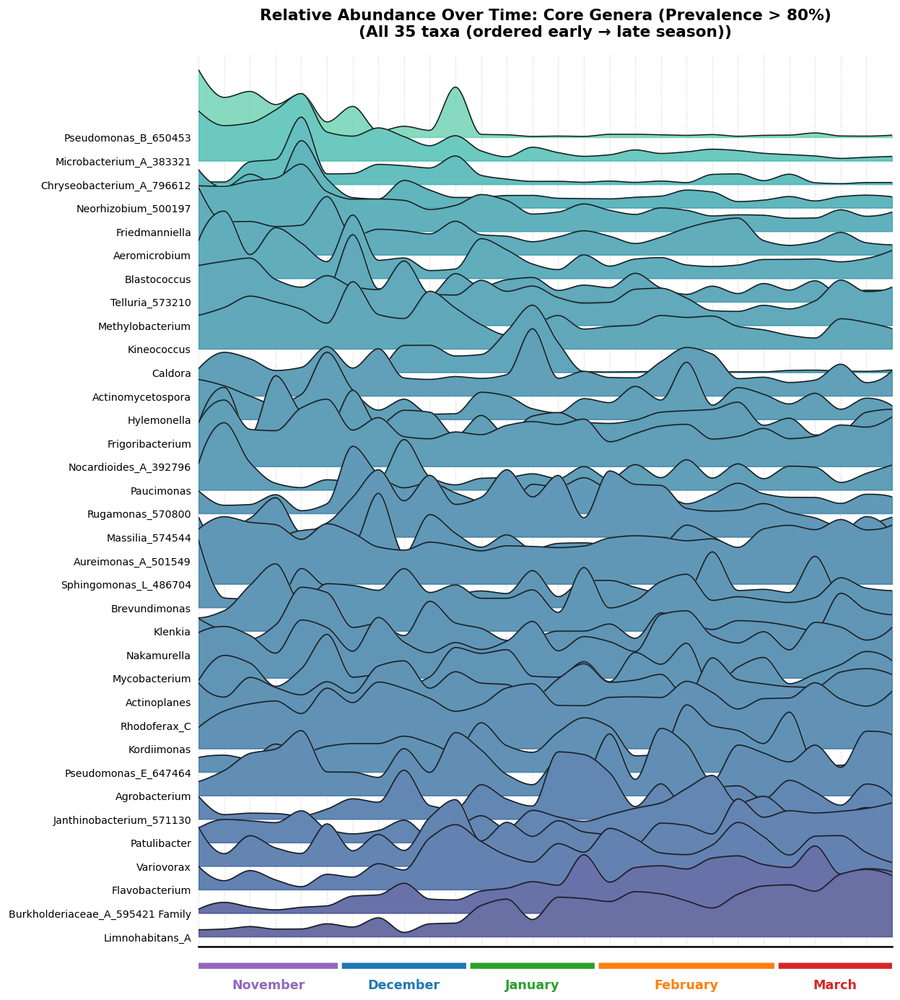

In [11]:
core_genus_info = genus_info.loc[genus_info["class"] == "Core"].copy()
print(f"Core genera count: {len(core_genus_info)}")

plot_labeled_joyplot(
    genus_tp_mean,
    core_genus_info,
    tax_col="Genus",
    title="Relative Abundance Over Time: Core Genera (Prevalence > 80%)",
    max_taxa=None,
    cmap_name="mako_r",
    save_path=figure_dir / "joyplot_genus_core.pdf",
)


### 2.3 Accessory Genera Over Time (10% ≤ Prevalence ≤ 80%)


Accessory genera count: 95


Saved figure to /Users/michael/Git/Outdoor_microbiome/Recalled_species_update_results/Figures/joyplot_genus_accessory_top40.pdf


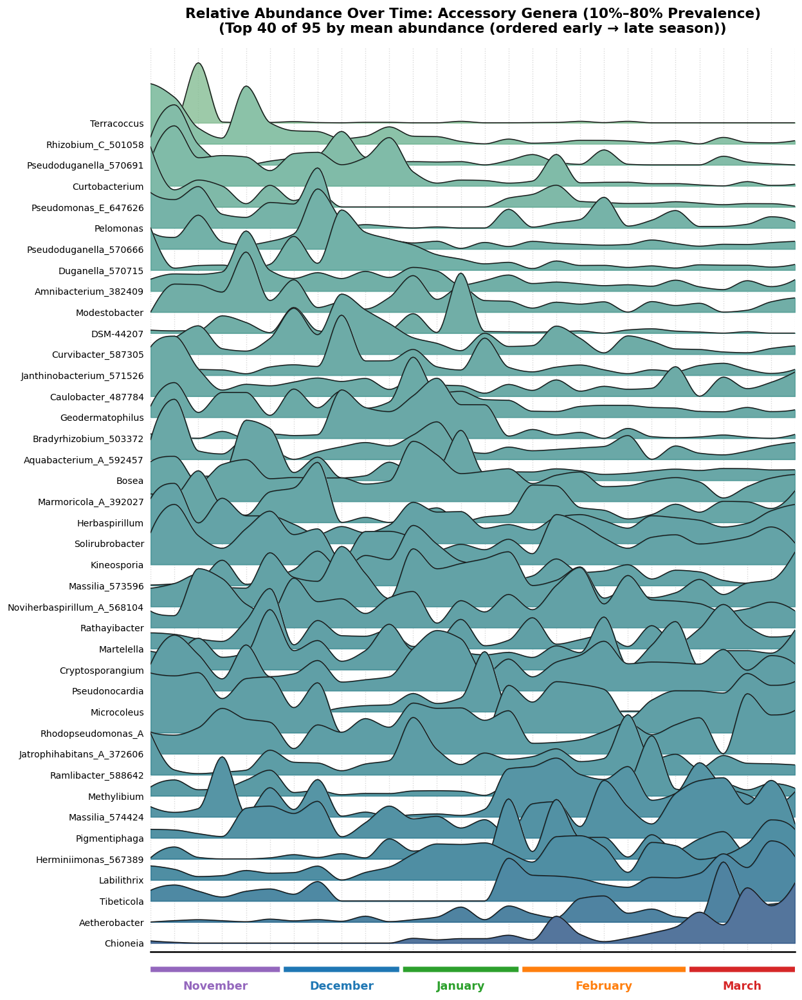

Saved figure to /Users/michael/Git/Outdoor_microbiome/Recalled_species_update_results/Figures/joyplot_genus_accessory_compact.pdf


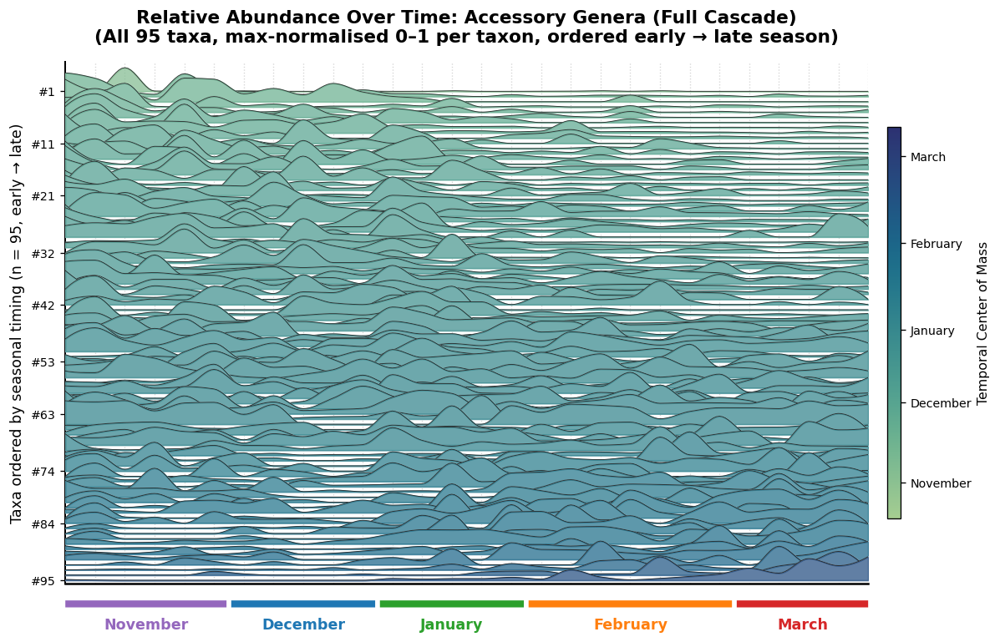

In [12]:
accessory_genus_info = genus_info.loc[genus_info["class"] == "Accessory"].copy()
print(f"Accessory genera count: {len(accessory_genus_info)}")

# 7a. Top 40 accessory genera by mean abundance (labeled joyplot)
plot_labeled_joyplot(
    genus_tp_mean,
    accessory_genus_info,
    tax_col="Genus",
    title="Relative Abundance Over Time: Accessory Genera (10%–80% Prevalence)",
    max_taxa=40,
    cmap_name="crest",
    save_path=figure_dir / "joyplot_genus_accessory_top40.pdf",
)

# 7b. All accessory genera (compact joyplot)
plot_compact_joyplot(
    genus_tp_mean,
    accessory_genus_info,
    tax_col="Genus",
    title="Relative Abundance Over Time: Accessory Genera (Full Cascade)",
    cmap_name="crest",
    save_path=figure_dir / "joyplot_genus_accessory_compact.pdf",
)


### 2.4 Rare Genera Over Time (Prevalence < 10%)


Rare genera count: 189


Saved figure to /Users/michael/Git/Outdoor_microbiome/Recalled_species_update_results/Figures/joyplot_genus_rare_top40.pdf


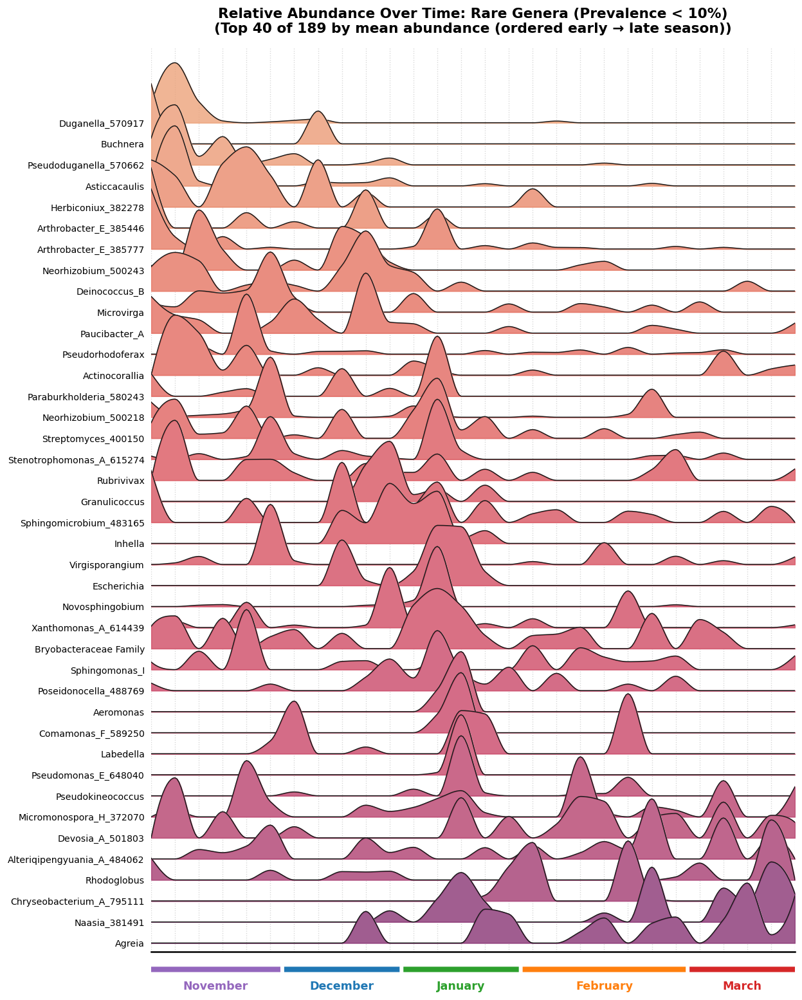

Saved figure to /Users/michael/Git/Outdoor_microbiome/Recalled_species_update_results/Figures/joyplot_genus_rare_compact.pdf


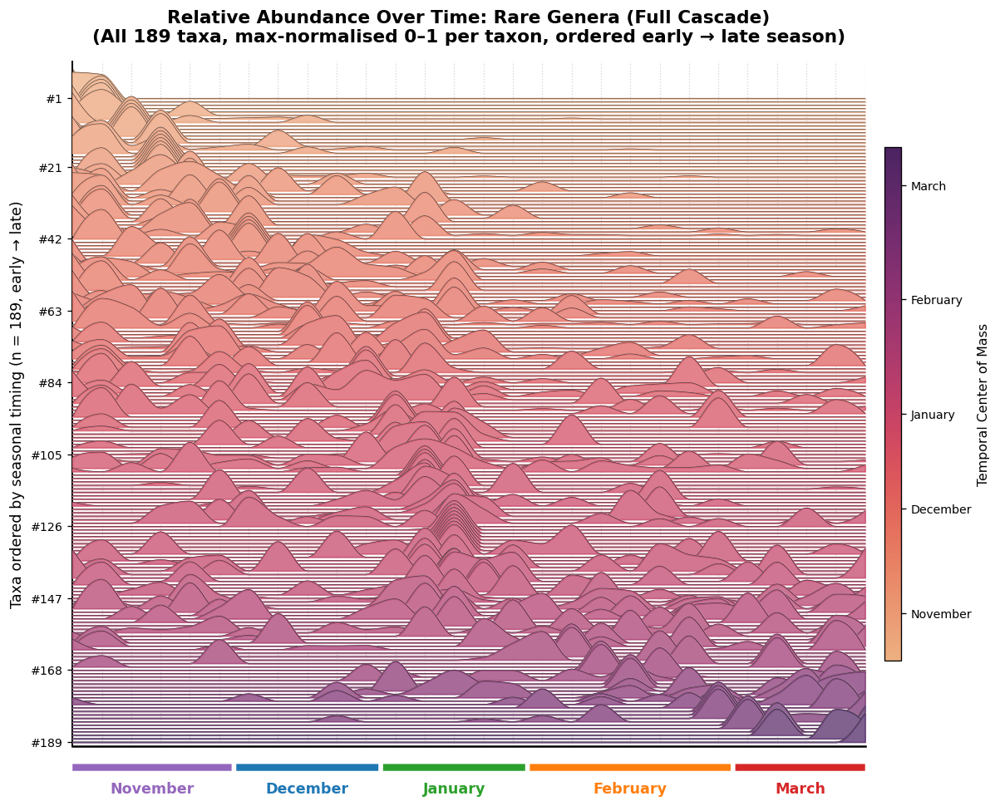

In [13]:
rare_genus_info = genus_info.loc[genus_info["class"] == "Rare"].copy()
print(f"Rare genera count: {len(rare_genus_info)}")

# 8a. Top 40 rare genera by mean abundance (labeled joyplot)
plot_labeled_joyplot(
    genus_tp_mean,
    rare_genus_info,
    tax_col="Genus",
    title="Relative Abundance Over Time: Rare Genera (Prevalence < 10%)",
    max_taxa=40,
    cmap_name="flare",
    save_path=figure_dir / "joyplot_genus_rare_top40.pdf",
)

# 8b. All rare genera (compact joyplot)
plot_compact_joyplot(
    genus_tp_mean,
    rare_genus_info,
    tax_col="Genus",
    title="Relative Abundance Over Time: Rare Genera (Full Cascade)",
    cmap_name="flare",
    save_path=figure_dir / "joyplot_genus_rare_compact.pdf",
)
